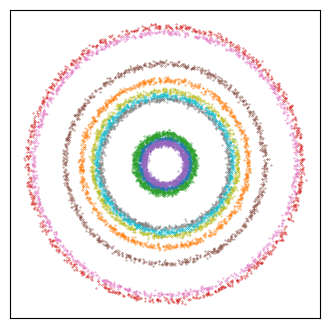

In [15]:
import time
import jax
import jax.numpy as jnp
import jax.random as jr
import equinox as eqx
import diffrax as dfx
import optax
import matplotlib.pyplot as plt

def sample_points_in_disk(key, n_points: int):
    theta = jr.uniform(key, shape=(n_points,)) * 2.0 * jnp.pi

    r = jr.uniform(key) * 0.9 + 0.1

    x = r * jnp.cos(theta)
    y = r * jnp.sin(theta)

    s = jnp.column_stack((x, y))

    return s + jr.normal(key, s.shape) * 0.01, jnp.full((n_points,), r)

key = jr.key(int(time.time()))

plt.figure(figsize=(4., 4.))
for i in range(10):
    key = jr.fold_in(key, i)
    X, Y = sample_points_in_disk(key, 1000)
    plt.scatter(*X.T, s=0.1)
plt.xticks([]) 
plt.yticks([])
plt.show()

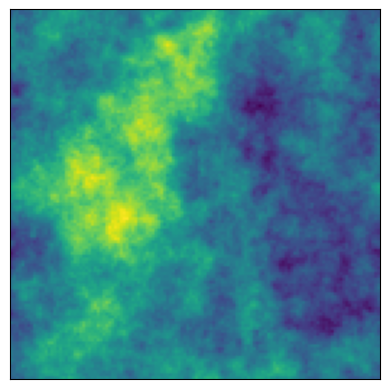

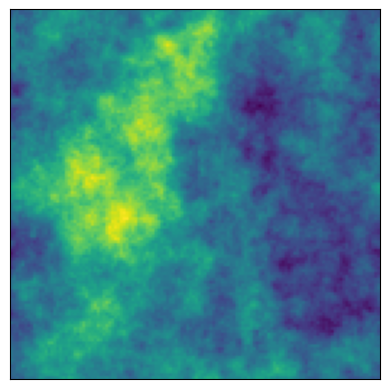

In [16]:
def grf2d_powerlaw(
    key,
    A: float,
    B: float,
    n: int,
    L: float,
    k0: float = 1.0,
    mean: float = 0.0,
    zero_mode: float = 0.0,
    eps: float = 1e-12,
):
    # Frequencies (cycles per unit length) -> convert to angular wavenumbers (2π * freq)
    kx = 2.0 * jnp.pi * jnp.fft.fftfreq(n, d=L / n)      # shape (n,)
    ky = 2.0 * jnp.pi * jnp.fft.rfftfreq(n, d=L / n)     # shape (n//2 + 1,)

    KX, KY = jnp.meshgrid(kx, ky, indexing="ij")         # shapes (n, n//2+1)
    k = jnp.sqrt(KX**2 + KY**2)

    # Power spectrum
    # Avoid k=0 issues with eps; we'll override the exact zero mode anyway.
    Pk = A * jnp.power((jnp.maximum(k, eps) / k0), B)

    # Draw complex Gaussian coefficients with variance ~Pk:
    # F = (N(0,1)+iN(0,1)) * sqrt(Pk/2)
    key_re, key_im = jax.random.split(key, 2)
    re = jax.random.normal(key_re, shape=Pk.shape)
    im = jax.random.normal(key_im, shape=Pk.shape)
    F = (re + 1j * im) * jnp.sqrt(Pk / 2.0)

    # Set k=0 mode explicitly (mean control)
    F = F.at[0, 0].set(zero_mode + 0.0j)

    # Inverse FFT to real space (JAX uses numpy-style normalization: irfftn includes 1/N)
    field = jnp.fft.irfftn(F, s=(n, n))

    # Optional: normalize overall scaling to be less "FFT-convention dependent".
    # This makes typical field variance scale more directly with A when changing n.
    # If you prefer raw FFT convention, remove the * (n*n)**0.5 factor.
    field = field * jnp.sqrt(n * n)

    return field + mean

import jax
import jax.numpy as jnp

def gaussian_to_lognormal_delta(g: jnp.ndarray, axis=None, clip=None) -> jnp.ndarray:
    # (Optional) enforce zero-mean before mapping; helps if your GRF has residual mean
    g0 = g - jnp.mean(g, axis=axis, keepdims=True)
    var = jnp.var(g0, axis=axis, keepdims=True)

    if clip is not None:
        g0 = jnp.clip(g0, -clip, clip)

    return jnp.exp(g0 - 0.5 * var) - 1.0


def gaussian_to_lognormal_positive(g: jnp.ndarray, axis=None, clip=None) -> jnp.ndarray:
    g0 = g - jnp.mean(g, axis=axis, keepdims=True)
    var = jnp.var(g0, axis=axis, keepdims=True)

    if clip is not None:
        g0 = jnp.clip(g0, -clip, clip)

    return jnp.exp(g0 - 0.5 * var)

key = jax.random.PRNGKey(0)
f = grf2d_powerlaw(key, n=128, L=1.0, A=1.0, B=-3.0, k0=2.0*jnp.pi)

plt.figure()
plt.imshow(f)
plt.xticks([])
plt.yticks([])
plt.show()

plt.figure()
plt.imshow(gaussian_to_lognormal_positive(f))
plt.xticks([])
plt.yticks([])
plt.show()

In [17]:
from dataclasses import dataclass
from functools import partial
import jax
import jax.numpy as jnp


def clip_time(t, eps=1e-6):
    t = jnp.clip(t, eps, 1. - eps)
    return t


@partial(
    jax.tree_util.register_dataclass,
    data_fields=[],
    meta_fields=[]
)
@dataclass
class OptimalTransportPath:

    def alpha(self, t):
        t = clip_time(t)
        return t 

    def sigma(self, t):
        t = clip_time(t)
        return 1. - t 

    def p_t(self, t, x_t, x):
        loc = self.alpha(t) * x
        scale = self.sigma(t) # std, not variance
        return jax.scipy.stats.norm.logpdf(x_t, loc=loc, scale=scale)

    def psi_t(self, t, x, z):
        return self.alpha(t) * x + self.sigma(t) * z

    def d_psi_t_dt(self, t, x, z):
        # u = jax.jacfwd(self.psi_t)(t, x, z)
        return x - z

    def d_alpha_dt(self, t):
        return jax.jacfwd(self.alpha)(t)

    def d_sigma_dt(self, t):
        return jax.jacfwd(self.sigma)(t)

In [18]:
def sample_tree_like():
    ...

In [19]:
key = jr.key(0)

# Data
n_samples = 1000
n_channels = 1
n_pix = 32
data_dim = n_pix ** 2
image_shape = (n_channels, n_pix, n_pix)
parameter_shape = (2,)
# Model
t_emb_dim = 8
sigma_min = 1e-3
patch_size = 2
num_patches = (n_pix // patch_size) ** 2
embedding_dim = 32
n_blocks = 3
# Training
n_steps = 100_000
n_batch = 256
opt = optax.adamw(learning_rate=1e-3)
# Sampling 
n_samples = 4
t0 = 0.
t1 = 1.
dt0 = 1e-2
solver = dfx.Heun()
sigma_sde = 0.3

non_gaussian_p_0 = False 

path = OptimalTransportPath()
sde_name = path.__class__.__name__.removesuffix("Path").lower()

# Dimensions into encoder?
modality_dims = dict()

In [20]:
key_A, key_B = jr.split(key)
A = jr.uniform(key_A, (n_samples,), minval=1.0, maxval=3.0)
B = jr.uniform(key_B, (n_samples,), minval=1.0, maxval=3.0) * -1.

generator = lambda key, A, B: grf2d_powerlaw(key, n=n_pix, L=1.0, A=A, B=B, k0=2.0 * jnp.pi)

keys = jr.split(key, len(A))
X = jax.vmap(generator)(keys, A, B)
X = X[:, jnp.newaxis, :, :]

Y = jnp.stack([A, B], axis=1)

In [21]:
modality_infos = {
    "x": {"shape": image_shape},
    "y": {"shape": parameter_shape}
}
len(modality_infos)

2

In [22]:
from typing import Callable

class Processor(eqx.Module):
    forward: Callable
    reverse: Callable

    def __init__(self, forward, reverse):
        self.forward = forward
        self.reverse = reverse

mu_x = jnp.mean(X)
std_x = jnp.std(X)

processor = Processor(
    forward=lambda x: (x - mu_x) / std_x,
    reverse=lambda x: x * std_x + mu_x
)

In [23]:
from functools import partial


def get_timestep_embedding(
    timesteps: jax.typing.ArrayLike, 
    embedding_dim: int, 
    dtype=jnp.float32
) -> jax.Array:
    # Convert scalar timesteps to an array
    if jnp.isscalar(timesteps):
        timesteps = jnp.array(timesteps, dtype=dtype)
        timesteps = jnp.atleast_1d(timesteps)
    assert len(timesteps.shape) == 1
    timesteps *= 1000.
    half_dim = embedding_dim // 2
    emb = jnp.log(10_000.) / (half_dim - 1.)
    emb = jnp.exp(jnp.arange(half_dim, dtype=dtype) * -emb)
    emb = timesteps.astype(dtype) * emb
    emb = jnp.concatenate([jnp.sin(emb), jnp.cos(emb)], axis=0)
    if embedding_dim % 2 == 1:  # Zero pad
        emb = jax.lax.pad(emb, dtype(0), ((0, 0, 0), (0, 1, 0)))
    assert emb.shape == (embedding_dim,)
    return emb


def get_time_embedder(embedding_dim):
    return partial(get_timestep_embedding, embedding_dim=embedding_dim)

In [ ]:
from typing import Optional
from jaxtyping import Array, Float, PRNGKeyArray
from einops import rearrange


class PatchEmbedding(eqx.Module):
    linear: eqx.nn.Linear
    patch_size: int
    position_embedding: Array

    def __init__(
        self,
        input_channels: int,
        output_shape: int,
        patch_size: int,
        num_patches: int,
        embedding_dim: int,
        key: PRNGKeyArray,
    ):
        self.patch_size = patch_size

        self.linear = eqx.nn.Linear(
            self.patch_size ** 2 * input_channels,
            output_shape,
            key=key
        )

        # NOTE: pos embed had extra dim for cls_token
        self.position_embedding = jr.normal(key, (num_patches, embedding_dim)) * 0.02

    def __call__(
        self, 
        x: Float[Array, "channels height width"],
        position_embed: bool = True
    ) -> Float[Array, "num_patches embedding_dim"]:
        x = rearrange(
            x,
            "c (h ph) (w pw) -> (h w) (c ph pw)",
            ph=self.patch_size,
            pw=self.patch_size,
        )

        x = jax.vmap(self.linear)(x)

        if position_embed:
            x = x + self.position_embedding

        return x


class AdaLayerNorm(eqx.Module):
    ln: eqx.nn.LayerNorm
    scale_proj: eqx.nn.Linear
    shift_proj: eqx.nn.Linear

    def __init__(self, embed_dim: int, *, key, eps=1e-5):
        k1, k2, k3 = jax.random.split(key, 3)

        self.ln = eqx.nn.LayerNorm(
            shape=embed_dim, eps=eps, use_bias=False, use_weight=False
        )

        # Output shape (dim,) and zero init
        self.scale_proj = eqx.nn.Linear(
            embed_dim, embed_dim, key=k2, use_bias=True
        )
        self.shift_proj = eqx.nn.Linear(
            embed_dim, embed_dim, key=k3, use_bias=True
        )

        # Zero init for scale and shift
        self.scale_proj = eqx.tree_at(
            lambda m: m.weight, 
            self.scale_proj, 
            jnp.zeros_like(self.scale_proj.weight)
        )
        self.scale_proj = eqx.tree_at(
            lambda m: m.bias, 
            self.scale_proj, 
            jnp.zeros_like(self.scale_proj.bias)
        )

        self.shift_proj = eqx.tree_at(
            lambda m: m.weight, 
            self.shift_proj, 
            jnp.zeros_like(self.shift_proj.weight)
        )
        self.shift_proj = eqx.tree_at(
            lambda m: m.bias, 
            self.shift_proj, 
            jnp.zeros_like(self.shift_proj.bias)
        )

    def __call__(self, x: jnp.ndarray, c: jnp.ndarray) -> jnp.ndarray:
        if c is None:
            return self.ln(x)
        scale = self.scale_proj(c)
        shift = self.shift_proj(c)
        return self.ln(x) * (1. + scale) + shift


class AttentionBlock(eqx.Module):
    layer_norm1: AdaLayerNorm
    layer_norm2: AdaLayerNorm
    attention: eqx.nn.MultiheadAttention
    linear1: eqx.nn.Linear
    linear2: eqx.nn.Linear
    dropout1: eqx.nn.Dropout
    dropout2: eqx.nn.Dropout

    def __init__(
        self,
        input_shape: int,
        hidden_dim: int,
        num_heads: int,
        dropout_rate: float,
        key: PRNGKeyArray,
    ):
        key1, key2, key3 = jr.split(key, 3)

        self.layer_norm1 = AdaLayerNorm(input_shape, key=key)
        self.layer_norm2 = AdaLayerNorm(input_shape, key=key)
        self.attention = eqx.nn.MultiheadAttention(num_heads, input_shape, key=key1)

        self.linear1 = eqx.nn.Linear(input_shape, hidden_dim, key=key2)
        self.linear2 = eqx.nn.Linear(hidden_dim, input_shape, key=key3)
        self.dropout1 = eqx.nn.Dropout(dropout_rate)
        self.dropout2 = eqx.nn.Dropout(dropout_rate)

    def __call__(
        self,
        x: Float[Array, "num_patches embedding_dim"],
        c: Optional[Float[Array, "embedding_dim"]] = None,
        mask: Optional[Float[Array, "num_patches embedding_dim"]] = None,
        key: Optional[PRNGKeyArray] = None,
    ) -> Float[Array, "num_patches embedding_dim"]:

        input_x = jax.vmap(eqx.Partial(self.layer_norm1, c=c))(x)
        x = x + self.attention(input_x, input_x, input_x, mask=mask)

        input_x = jax.vmap(eqx.Partial(self.layer_norm2, c=c))(x)
        input_x = jax.vmap(self.linear1)(input_x)
        input_x = jax.nn.gelu(input_x)

        if key is not None:
            key1, key2 = jr.split(key, num=2)
        else:
            key1 = key2 = None

        input_x = self.dropout1(input_x, key=key1)
        input_x = jax.vmap(self.linear2)(input_x)
        input_x = self.dropout2(input_x, key=key2)

        x = x + input_x

        return x


class VisionTransformer(eqx.Module):
    cls_token: jnp.ndarray
    attention_blocks: list[AttentionBlock]
    dropout: eqx.nn.Dropout
    mlp: eqx.nn.Sequential
    num_layers: int

    def __init__(
        self,
        output_dim: int,
        embedding_dim: int,
        hidden_dim: int,
        num_heads: int,
        num_layers: int,
        dropout_rate: float,
        key: PRNGKeyArray,
    ):
        key1, key2, key3, key4, key5 = jr.split(key, 5)

        self.cls_token = jr.normal(key3, (1, embedding_dim))

        self.num_layers = num_layers

        self.attention_blocks = [
            AttentionBlock(
                embedding_dim, hidden_dim, num_heads, dropout_rate, key=key4
            )
            for _ in range(self.num_layers)
        ]

        self.dropout = eqx.nn.Dropout(dropout_rate)

        self.mlp = eqx.nn.Sequential(
            [
                eqx.nn.LayerNorm(embedding_dim),
                eqx.nn.Linear(embedding_dim, output_dim, key=key5),
            ]
        )

    def __call__(
        self,
        x: Float[Array, "s e"],
        c: Optional[Float[Array, "e"]],
        mask: Optional[Float[Array, "s e"]] = None,
        *,
        key: Optional[PRNGKeyArray] = None,
        use_class_token: bool = False
    ) -> Float[Array, "s e"]:

        if use_class_token:
            x = jnp.concatenate([self.cls_token, x])

        # if c is not None:
            # c = jnp.atleast_2d(c)
            # x = jnp.concatenate([x, c])

        # x += self.positional_embedding[
        #     : x.shape[0]
        # ]  # Slice to the same length as x, as the positional embedding may be longer.

        if key is not None:
            dropout_key, *attention_keys = jr.split(key, num=self.num_layers + 1)
        else:
            dropout_key = None
            attention_keys = [None] * len(self.attention_blocks)

        x = self.dropout(x, key=dropout_key)

        for block, attention_key in zip(self.attention_blocks, attention_keys):
            x = block(x, c=c, mask=mask, key=attention_key)

        # x = x[0]  # Select the CLS token.
        # x = jax.vmap(self.mlp)(x)

        return x


class ParameterDecoder(eqx.Module):
    linear: eqx.nn.Linear

    def __init__(self, embedding_dim, dim, key):
        self.linear = eqx.nn.Linear(4, dim, key=key)

    def __call__(self, p):
        return self.linear(jnp.squeeze(p, axis=0)) # Remove axis from sequence stacking

- modalities may be images, then require patch embedding
    - get `ModalitiesEncoder` to respect this

In [25]:
def input_to_modality_dict(x, q, t):
    x, q, t = map(jnp.atleast_2d, (x, q, t))
    d = dict(x=x, q=q, t=t)
    return d

def modality_dict_to_sequence(d):
    # Tag modalities in sequence with ID?
    sequence = jnp.concatenate(jax.tree.leaves(d))
    t = d.pop("t") # Possibly just add time to all modalities here
    if t is not None:
        sequence = sequence + t
    return sequence

In [ ]:
from math import prod

def _get_modality_encoder_module(name, dim, embedding_dim, key):
    if name != "x":
        module = eqx.nn.Linear(dim, embedding_dim, key=key)
    else:
        module = PatchEmbedding(
            input_channels=n_channels, 
            output_shape=embedding_dim, 
            patch_size=patch_size,
            embedding_dim=embedding_dim,
            num_patches=num_patches,
            key=key
        )
    return module
    

def unpatchify(x, *, image_shape, patch_size):
    c, H, W = image_shape
    ph = pw = patch_size
    h = H // ph
    w = W // pw
    assert x.shape[0] == h * w, (x.shape, h, w)
    assert x.shape[1] == c * ph * pw, (x.shape, c, ph, pw)

    return rearrange(
        x,
        "(h w) (c ph pw) -> c (h ph) (w pw)",
        h=h, w=w, c=c, ph=ph, pw=pw
    )


def _get_modality_decoder_module(name, dim, embedding_dim, key):
    if name == "x":
        module = lambda x: unpatchify(x, image_shape=image_shape, patch_size=patch_size)
    else:
        module = ParameterDecoder(embedding_dim, dim, key=key)
    return module


def _get_encoders(encoders, keys):
    return dict(zip(keys, [encoders[key] for key in keys]))


def _get_decoders(decoders, keys):
    return dict(zip(keys, [decoders[key] for key in keys]))


class ModalitiesEncoder(eqx.Module):
    encoders: dict[str, eqx.Module]

    def __init__(
        self, 
        embedding_dim: int, 
        modality_infos: dict[str, dict], 
        *, 
        key: PRNGKeyArray
    ):
        self.encoders = dict(
            zip(
                modality_infos.keys(),
                [
                    _get_modality_encoder_module(
                        _key, 
                        prod(modality_infos[_key]["shape"]), 
                        embedding_dim, 
                        key=jr.fold_in(key, k)
                    )
                    for k, _key in enumerate(modality_infos.keys())
                ]
            )
        )

    def __call__(self, d, stacked=False):
        e = jax.tree.map(
            lambda d, e: jnp.atleast_2d(e(d)), 
            d, 
            _get_encoders(self.encoders, keys=d.keys())
        )
        if stacked:
            e = jnp.concatenate(jax.tree.leaves(e))
        return e


class ModalitiesDecoder(eqx.Module):
    decoders: dict[str, eqx.Module | ParameterDecoder]

    def __init__(
        self, 
        embedding_dim: int, 
        modality_infos: dict[str, dict], 
        *, 
        key: PRNGKeyArray
    ):
        self.decoders = dict(
            zip(
                modality_infos.keys(),
                [
                    _get_modality_decoder_module(
                        _key, 
                        prod(modality_infos[_key]["shape"]), 
                        embedding_dim, 
                        key=jr.fold_in(key, k)
                    )
                    for k, _key in enumerate(modality_infos.keys())
                ]
            )
        )

    def __call__(self, e):
        d = jax.tree.map(
            lambda e, d: d(e),
            e, 
            _get_decoders(self.decoders, keys=e.keys())
        )
        return d

In [ ]:
from jaxtyping import Scalar, Bool

Modalities = dict[str, Array]

class FlowTransformer(eqx.Module):
    modalities_encoder: ModalitiesEncoder
    modalities_decoder: ModalitiesDecoder
    transformer: VisionTransformer
    time_embedder: eqx.Module

    def __init__(
        self, 
        modalities_encoder: ModalitiesEncoder, 
        modalities_decoder: ModalitiesDecoder, 
        transformer: VisionTransformer,
        time_embedder: eqx.Module
    ):
        self.modalities_encoder = modalities_encoder
        self.modalities_decoder = modalities_decoder
        self.transformer = transformer
        self.time_embedder = time_embedder

    def encode(self, d):
        e = self.modalities_encoder(d, stacked=True)
        return e

    def attention(self, d):
        ... # E.g. not using regressor mlp-head

    def __call__(
        self, 
        d: Modalities, 
        t: Optional[Scalar] = None, 
        mask: Optional[Bool[Array, "..."]] = None
    ):
        # Embed time as a condition into attention / MLP / LayerNorms
        # not as a token!
        if t is not None:
            c = self.time_embedder(t)
        else:
            c = None
        # Record input shapes for use in reconstructing the output
        # modalities that are present or not
        e = self.modalities_encoder(d)
        shapes = jax.tree.map(jnp.shape, e)
        # Stack modalities and input to transformer
        e = jnp.concatenate(jax.tree.leaves(e))
        h = self.transformer(e, c, mask=mask)
        v = jax.vmap(self.transformer.mlp)(h) # NOTE: not necessary?
        # Get sizes to split v into each modality
        dims = jax.tree.map(lambda s: s[0], shapes, is_leaf=lambda l: isinstance(l, tuple))
        lengths = jnp.cumsum(jnp.array(jax.tree.leaves(dims)))[:-1]
        v = jnp.split(v, lengths) # Should accumulate dims?
        v = jax.tree.unflatten(jax.tree.structure(d), v)
        v = self.modalities_decoder(v)
        return v


modalities_encoder = ModalitiesEncoder(
    embedding_dim, modality_infos, key=key
)

modalities_decoder = ModalitiesDecoder(
    embedding_dim, modality_infos, key=key
)

transformer = VisionTransformer(
    output_dim=n_channels * patch_size ** 2, # (n_pix // patch_size) ** 2, # prod(image_shape),
    embedding_dim=embedding_dim,
    hidden_dim=128,
    num_heads=8,
    num_layers=4,
    dropout_rate=0.,
    key=key
)

time_embedder = get_time_embedder(embedding_dim)

v = FlowTransformer(
    modalities_encoder, 
    modalities_decoder, 
    transformer,
    time_embedder
)

v = eqx.nn.inference_mode(v)

# d = dict(x=jnp.ones((n_channels, n_pix, n_pix)), y=jnp.ones((2,)))

# v(d).shape

In [28]:
t = jnp.ones(())

d = dict(x=jnp.ones((n_channels, n_pix, n_pix)), y=jnp.ones((2,)))

jax.tree.map(jnp.shape, v(d, t=t))

{'x': (1, 32, 32), 'y': (2,)}

In [29]:
t = jnp.ones(())

d = dict(x=jnp.ones((n_channels, n_pix, n_pix)))

o = v(d, t=t)

jax.tree.map(jnp.shape, o)

{'x': (1, 32, 32)}

In [30]:
# Now allow for a mask

t = jnp.ones(())

d = dict(x=jnp.ones((n_channels, n_pix, n_pix)))

n_seq = (n_pix // patch_size) ** 2 

mask = jnp.ones((n_seq, n_seq)) # NOTE: should have 

o = v(d, t=t, mask=mask)

jax.tree.map(jnp.shape, o)

{'x': (1, 32, 32)}

In [31]:
# Now allow for a mask

t = jnp.ones(())

d = dict(x=jnp.ones((n_channels, n_pix, n_pix)), y=jnp.ones((2,)))

n_seq = (n_pix // patch_size) ** 2 + 1

mask = jnp.ones((n_seq, n_seq)) # NOTE: dtype?

o = v(d, t=t, mask=mask)

jax.tree.map(jnp.shape, o)

{'x': (1, 32, 32), 'y': (2,)}

In [32]:
@eqx.filter_jit
def single_sample_fn_ode(v, x_0, times=None):

    def velocity(t, x, args):
        (v,) = args
        return v(x, t=t)
    
    v = eqx.tree_inference(v, True)

    saveat = dfx.SaveAt(ts=times) if times is not None else dfx.SaveAt(t1=True)

    term = dfx.ODETerm(velocity) 
    sol = dfx.diffeqsolve(
        term, 
        solver, 
        t0, 
        t1, 
        dt0, 
        x_0, 
        args=(v,),
        saveat=saveat
    )

    # if times is not None:
    #     x_1 = sol.ys
    # else:
    #     (x_1,) = sol.ys

    x_1 = sol.ys

    # Magical strange axis appearing...
    x_1 = jax.tree.map(
        lambda x: jnp.squeeze(x, axis=0),
        x_1
    )

    return x_1


@eqx.filter_jit
def single_sample_fn_ode_(v, x_0, modalities_to_sample=None, times=None):

    # Gather masks for modalities that should not be sampled
    if modalities_to_sample is not None:
        masks = []
        for name in modalities_to_sample:
            if name not in x_0.keys():
                masks.append(jnp.zeros_like(x_0[name]))
            else:
                masks.append(jnp.ones_like(x_0[name]))

    def velocity(t, x, args):
        (v,) = args
        return v(x, t=t)
    
    v = eqx.tree_inference(v, True)

    saveat = dfx.SaveAt(ts=times) if times is not None else dfx.SaveAt(t1=True)

    term = dfx.ODETerm(velocity) 
    sol = dfx.diffeqsolve(
        term, 
        solver, 
        t0, 
        t1, 
        dt0, 
        x_0, 
        args=(v,),
        saveat=saveat
    )

    # if times is not None:
    #     x_1 = sol.ys
    # else:
    #     (x_1,) = sol.ys

    x_1 = sol.ys

    # Magical strange axis appearing...
    x_1 = jax.tree.map(
        lambda x: jnp.squeeze(x, axis=0),
        x_1
    )

    return x_1

In [33]:
from copy import deepcopy

opt_state = opt.init(eqx.filter(v, eqx.is_array))

def apply_ema(ema_model, model, ema_rate=0.999):
    m_, _m = eqx.partition(model, eqx.is_inexact_array)
    e_, _e = eqx.partition(ema_model, eqx.is_inexact_array)
    ema_fn = lambda p_ema, p: p_ema * ema_rate + p * (1. - ema_rate)
    e_ = jax.tree.map(ema_fn, e_, m_)
    return eqx.combine(e_, _m)

use_ema = True
if use_ema:
    v_ema = deepcopy(v)
else:
    v_ema = None

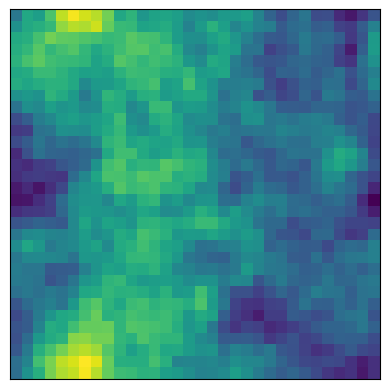

In [34]:
f = grf2d_powerlaw(key, n=n_pix, L=1.0, A=1.0, B=-3.0, k0=2.0*jnp.pi)

plt.figure()
plt.imshow(f)
plt.xticks([])
plt.yticks([])
plt.show()

In [ ]:
from tqdm.auto import trange


def get_time(key):
    t = jr.uniform(key, (n_batch,), minval=t0, maxval=t1 / n_batch)
    t = t + (t1 / n_batch) * jnp.arange(n_batch)
    return t


def _mse(y_, y):
    return jnp.mean(jnp.square(jnp.subtract(y_, y)))


def loss_fn(model, path, d, z, t):
    # Diffuse modalities in d according to same diffusion path
    u = jax.tree.map(
        lambda x, z: jax.vmap(path.d_psi_t_dt)(t, x, z),
        d,
        z
    )
    psi = jax.tree.map(
        lambda x, z: jax.vmap(path.psi_t)(t, x, z),
        d,
        z
    )
    u_ = jax.vmap(model)(psi, t)
    l = sum(jax.tree.leaves(jax.tree.map(_mse, u, u_)))
    # print("psi", jax.tree.map(jnp.shape, psi))
    # print("u", jax.tree.map(jnp.shape, u))
    # print("u_", jax.tree.map(jnp.shape, u_))
    return l


def tree_random_normal_like(tree, key, dtype=None):
    leaves, treedef = jax.tree.flatten(tree)
    keys = jr.split(key, len(leaves))
    new_leaves = [
        jr.normal(k, shape=leaf.shape, dtype=dtype or leaf.dtype)
        for k, leaf in zip(keys, leaves)
    ]
    return jax.tree_util.tree_unflatten(treedef, new_leaves)


@eqx.filter_jit(donate="all")
def make_step(v, path, key, X, Y, opt_state, v_ema=None):
    key_idx, key_t, key_step = jr.split(key, 3)

    idx_x, idx_z = jr.choice(key_idx, len(X), (2, n_batch))
    x, y = X[idx_x], Y[idx_x]
    t = get_time(key_t)

    d = dict(x=x, y=y) # Setup modality dictionary (NOTE: maybe one entry per model parameter?)

    z = tree_random_normal_like(d, key)

    grad_fn = eqx.filter_value_and_grad(loss_fn)
    loss, grads = grad_fn(v, path, d, z, t)

    updates, opt_state = opt.update(grads, opt_state, v)
    v = eqx.apply_updates(v, updates)

    if v_ema is not None:
        v_ema = apply_ema(v_ema, v)

    return v, loss, opt_state, v_ema


Z = dict(
    x=jr.normal(key, (n_samples ** 2,) + image_shape), 
    y=jr.normal(key, (n_samples ** 2,) + (2,))
)

L = []
with trange(n_steps, colour="green") as steps:
    for step in steps:
        key, key_step = jr.split(key)

        v, loss, opt_state, v_ema = make_step(
            v, path, key_step, X, Y, opt_state, v_ema=v_ema
        )

        steps.set_postfix(L=loss)
        L = L + [loss]

        if step % 100 == 0:
            samples_dict = jax.vmap(lambda z: single_sample_fn_ode(v, z))(Z)
            # print("samples", jax.tree.map(jnp.shape, samples_dict))
            samples = rearrange(
                samples_dict["x"], 
                "(p q) c h w -> (h p) (q w) c", 
                p=n_samples
            )

            plt.figure()
            plt.imshow(samples, cmap="PuOr")
            plt.savefig(f"samples/samples_{step:07d}.png")
            plt.xticks([])
            plt.yticks([])
            plt.close()

            plt.figure()
            plt.loglog(L)
            plt.savefig("loss.png")
            plt.close()

if v_ema is not None:
    v = v_ema

/Users/Jed.Homer/phd/generative_models/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
  0%|          | 0/100000 [00:06<?, ?it/s, L=4.56999]/var/folders/8t/4ygzv0nj53sdbz0dz587zwzh0000gq/T/ipykernel_46177/2200855367.py:103: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.savefig("loss.png")
  2%|▏         | 1594/100000 [9:46:10<87:29:01,  3.20s/it, L=0.27969718]   

In [ ]:
plt.figure()
plt.loglog(L)
plt.show()

In [ ]:
def mask_from_modality_keys():
    ... # Get mask for modalities that are being sampled or not algotether

In [ ]:
n_t_steps = 1000
times = jnp.linspace(t0, t1, n_t_steps)

In [ ]:
batch = {
    "x": jnp.ones((3, 32, 32)),
    "y": jnp.ones((3, 10)),
}

def f(example):
    return {
        "x": example["x"] * 2,
        "y": example["y"] + 1,
    }

vf = jax.vmap(f)   # default in_axes=0
out = vf(batch)
jax.tree.map(jnp.shape, out)

{'x': (3, 32, 32), 'y': (3, 10)}